Cleaned dataset: (4005, 24)
Original dataset: (4005, 19)

Tags recovered from original dataset.
Talks with non-empty tags: 4005

Prepared feature columns:
['title_feature', 'description_feature', 'transcript_feature', 'tags_feature']

SELECTED TED TALKS:


,talk_id,title
761,995,Glorious visions in animation and performance
1047,1307,Medicine for the 99 percent
1580,1879,What is so special about the human brain?
3479,41223,The mysterious science of pain
3153,32269,The uncomplicated truth about women's sexuality



Experiment 1 - Title Only
Matrix dimensions: (4005, 2510)

Experiment 2 - Title + Tags
Matrix dimensions: (4005, 7501)

Experiment 3 - Title + Description + Tags
Matrix dimensions: (4005, 12000)

Experiment 4 - Title + Description + Transcript + Tags
Matrix dimensions: (4005, 12000)

COMPLETE EXPERIMENT COMPARISON:


,Experiment,Selected Talk ID,Selected Talk,Rank,Recommended Talk ID,Recommended Talk,Similarity Score
0,Experiment 1 - Title Only,995,Glorious visions in animation and performance,1,796,Suspended animation is within our grasp,0.5841
1,Experiment 1 - Title Only,995,Glorious visions in animation and performance,2,199,"A performance of ""Mathemagic""",0.5636
2,Experiment 1 - Title Only,995,Glorious visions in animation and performance,3,13035,"Visions of Africa's future, from African filmm...",0.3624
3,Experiment 1 - Title Only,995,Glorious visions in animation and performance,4,2684,An electrifying acoustic guitar performance,0.3176
4,Experiment 1 - Title Only,995,Glorious visions in animation and performance,5,1611,A bath without water,0.0000
...,...,...,...,...,...,...,...
95,Experiment 4 - Title + Description + Transcrip...,32269,The uncomplicated truth about women's sexuality,1,32557,The science of sex,0.2523
96,Experiment 4 - Title + Description + Transcrip...,32269,The uncomplicated truth about women's sexuality,2,2708,What young women believe about their own sexua...,0.2311
97,Experiment 4 - Title + Description + Transcrip...,32269,The uncomplicated truth about women's sexuality,3,32555,A case for cliteracy,0.2273
98,Experiment 4 - Title + Description + Transcrip...,32269,The uncomplicated truth about women's sexuality,4,15813,The truth about unwanted arousal,0.2089



Experiment 1 - Title Only

Selected Talk: Glorious visions in animation and performance


,Rank,Recommended Talk,Similarity Score
0,1,Suspended animation is within our grasp,0.5841
1,2,"A performance of ""Mathemagic""",0.5636
2,3,"Visions of Africa's future, from African filmm...",0.3624
3,4,An electrifying acoustic guitar performance,0.3176
4,5,A bath without water,0.0000


... (36 outputs left out)


Selected Talk: The uncomplicated truth about women's sexuality


,Rank,Recommended Talk,Similarity Score
95,1,The science of sex,0.2523
96,2,What young women believe about their own sexua...,0.2311
97,3,A case for cliteracy,0.2273
98,4,The truth about unwanted arousal,0.2089
99,5,Are we designed to be sexual omnivores?,0.2051



RECOMMENDATION OVERLAP COMPARISON:


,Selected Talk,Experiment,Overlap with Title Only,Jaccard Similarity
0,Glorious visions in animation and performance,Experiment 1 - Title Only,5,1.000
1,Glorious visions in animation and performance,Experiment 2 - Title + Tags,0,0.000
2,Glorious visions in animation and performance,Experiment 3 - Title + Description + Tags,0,0.000
3,Glorious visions in animation and performance,Experiment 4 - Title + Description + Transcrip...,0,0.000
4,Medicine for the 99 percent,Experiment 1 - Title Only,5,1.000
5,Medicine for the 99 percent,Experiment 2 - Title + Tags,0,0.000
6,Medicine for the 99 percent,Experiment 3 - Title + Description + Tags,0,0.000
7,Medicine for the 99 percent,Experiment 4 - Title + Description + Transcrip...,0,0.000
8,What is so special about the human brain?,Experiment 1 - Title Only,5,1.000
9,What is so special about the human brain?,Experiment 2 - Title + Tags,0,0.000


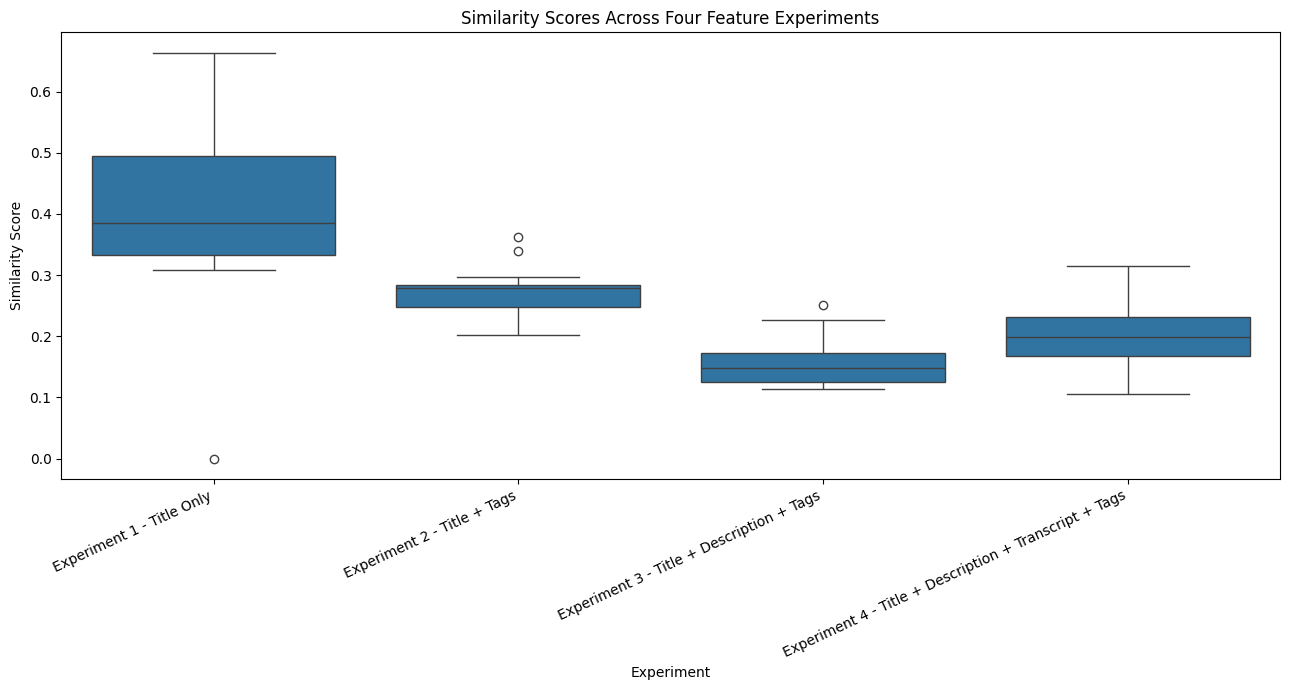


Manual evaluation sheet saved:
/content/task6_manual_relevance_evaluation.csv

TASK 6: FEATURE SELECTION REPORT
Number of TED Talks: 4005
Selected talks: 5
Number of experiments: 4
Total recommendation records: 100
Experiment 1 - Title Only | Vocabulary size: 2510
Experiment 2 - Title + Tags | Vocabulary size: 7501
Experiment 3 - Title + Description + Tags | Vocabulary size: 12000
Experiment 4 - Title + Description + Transcript + Tags | Vocabulary size: 12000

OBSERVATIONS TO COMPLETE:

1. Title-only recommendations depend mainly on title vocabulary.

2. Adding tags can improve topic-based matching when tags are
   available and informative.

3. Adding descriptions provides more contextual information.

4. Transcripts provide extensive content, but may introduce
   irrelevant words, repeated phrases and noise.

5. A higher cosine similarity score does not automatically
   mean a recommendation is more relevant.

6. Final feature selection must be based on manual relevance
   evaluatio

In [1]:

# ============================================================
# TASK 6: FEATURE SELECTION AND RECOMMENDATION QUALITY EVALUATION
# Notebook: 06_feature_selection_evaluation.ipynb
# ============================================================

import pandas as pd
import numpy as np
import ast
import re
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ------------------------------------------------------------
# 1. LOAD DATASETS
# ------------------------------------------------------------

CLEAN_PATH = "/content/ted_talks_cleaned.csv"
ORIGINAL_PATH = "/content/ted_talks_en.csv"

if not Path(CLEAN_PATH).exists() or not Path(ORIGINAL_PATH).exists():

    from google.colab import files

    print("Upload ted_talks_cleaned.csv and ted_talks_en.csv")
    files.upload()

df = pd.read_csv(CLEAN_PATH)

original_df = pd.read_csv(ORIGINAL_PATH)

print("Cleaned dataset:", df.shape)
print("Original dataset:", original_df.shape)

# ------------------------------------------------------------
# 2. RECOVER ORIGINAL TOPICS / TAGS
# ------------------------------------------------------------

def parse_tags(value):

    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    try:
        parsed = ast.literal_eval(str(value))

        if isinstance(parsed, list):
            return parsed

        if isinstance(parsed, dict):
            return list(parsed.values())

    except (ValueError, SyntaxError):
        pass

    return []


# Original dataset uses the column "topics"
if "topics" not in original_df.columns:
    raise ValueError("Original dataset does not contain topics.")

if "talk_id" not in original_df.columns:
    raise ValueError("Original dataset does not contain talk_id.")

original_tags = original_df[
    ["talk_id", "topics"]
].copy()

original_tags["tags_text"] = (
    original_tags["topics"]
    .apply(parse_tags)
    .apply(lambda x: " ".join(str(tag) for tag in x))
)

original_tags = original_tags[
    ["talk_id", "tags_text"]
].drop_duplicates(subset="talk_id")

df = df.merge(
    original_tags,
    on="talk_id",
    how="left"
)

df["tags_text"] = df["tags_text"].fillna("")

print("\nTags recovered from original dataset.")

print("Talks with non-empty tags:",
      (df["tags_text"].str.strip() != "").sum())

# ------------------------------------------------------------
# 3. PREPARE TEXT FEATURES
# ------------------------------------------------------------

def get_text_column(df, column, cleaned_column=None):

    if cleaned_column and cleaned_column in df.columns:

        return df[cleaned_column].fillna("").astype(str)

    if column in df.columns:

        return df[column].fillna("").astype(str)

    return pd.Series("", index=df.index)


df["title_feature"] = get_text_column(
    df, "title", "title_clean"
)

df["description_feature"] = get_text_column(
    df, "description", "description_clean"
)

df["transcript_feature"] = get_text_column(
    df, "transcript", "transcript_clean"
)

df["tags_feature"] = df["tags_text"].astype(str)

df = df[
    df["title_feature"].str.strip() != ""
].copy()

df.reset_index(drop=True, inplace=True)

print("\nPrepared feature columns:")
print([
    "title_feature",
    "description_feature",
    "transcript_feature",
    "tags_feature"
])

# ------------------------------------------------------------
# 4. DEFINE FOUR EXPERIMENTS
# ------------------------------------------------------------

experiments = {

    "Experiment 1 - Title Only":

        ["title_feature"],

    "Experiment 2 - Title + Tags":

        ["title_feature", "tags_feature"],

    "Experiment 3 - Title + Description + Tags":

        [
            "title_feature",
            "description_feature",
            "tags_feature"
        ],

    "Experiment 4 - Title + Description + Transcript + Tags":

        [
            "title_feature",
            "description_feature",
            "transcript_feature",
            "tags_feature"
        ]
}

# ------------------------------------------------------------
# 5. SELECT FIVE ACTUAL TED TALKS
# ------------------------------------------------------------

selected_df = df.sample(
    n=min(5, len(df)),
    random_state=42
).copy()

selected_indices = selected_df.index.tolist()

print("\nSELECTED TED TALKS:")

display(
    selected_df[["talk_id", "title"]]
)

# ------------------------------------------------------------
# 6. GENERATE RECOMMENDATIONS FOR EACH EXPERIMENT
# ------------------------------------------------------------

all_results = []

experiment_models = {}

for experiment_name, columns in experiments.items():

    print("\n" + "=" * 75)
    print(experiment_name)
    print("=" * 75)

    # Combine selected features
    experiment_text = (
        df[columns]
        .fillna("")
        .astype(str)
        .agg(" ".join, axis=1)
    )

    # Build TF-IDF model
    vectorizer = TfidfVectorizer(
        stop_words="english",
        max_features=12000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True
    )

    matrix = vectorizer.fit_transform(experiment_text)

    experiment_models[experiment_name] = {
        "vectorizer": vectorizer,
        "matrix": matrix
    }

    print("Matrix dimensions:", matrix.shape)

    # Generate recommendations for five talks
    for selected_index in selected_indices:

        scores = cosine_similarity(
            matrix[selected_index],
            matrix
        ).flatten()

        # Exclude selected talk
        scores[selected_index] = -1

        top_indices = np.argsort(scores)[::-1][:5]

        for rank, recommended_index in enumerate(
            top_indices,
            start=1
        ):

            all_results.append({

                "Experiment": experiment_name,

                "Selected Talk ID":
                    df.iloc[selected_index]["talk_id"],

                "Selected Talk":
                    df.iloc[selected_index]["title"],

                "Rank": rank,

                "Recommended Talk ID":
                    df.iloc[recommended_index]["talk_id"],

                "Recommended Talk":
                    df.iloc[recommended_index]["title"],

                "Similarity Score":
                    round(float(scores[recommended_index]), 4)

            })

# ------------------------------------------------------------
# 7. CREATE COMPARISON DATAFRAME
# ------------------------------------------------------------

results_df = pd.DataFrame(all_results)

print("\nCOMPLETE EXPERIMENT COMPARISON:")

display(results_df)

# ------------------------------------------------------------
# 8. DISPLAY RECOMMENDATIONS EXPERIMENT-WISE
# ------------------------------------------------------------

for experiment_name in experiments:

    print("\n" + "=" * 75)
    print(experiment_name)
    print("=" * 75)

    experiment_results = results_df[
        results_df["Experiment"] == experiment_name
    ]

    for selected_title in selected_df["title"]:

        print("\nSelected Talk:", selected_title)

        output = experiment_results[
            experiment_results["Selected Talk"] == selected_title
        ][[
            "Rank",
            "Recommended Talk",
            "Similarity Score"
        ]]

        display(output)

# ------------------------------------------------------------
# 9. COMPARE RECOMMENDATION OVERLAP
# ------------------------------------------------------------

overlap_results = []

for selected_title in selected_df["title"]:

    reference_set = set(
        results_df[
            (results_df["Selected Talk"] == selected_title) &
            (results_df["Experiment"] ==
             "Experiment 1 - Title Only")
        ]["Recommended Talk ID"]
    )

    for experiment_name in experiments:

        current_set = set(
            results_df[
                (results_df["Selected Talk"] == selected_title) &
                (results_df["Experiment"] == experiment_name)
            ]["Recommended Talk ID"]
        )

        intersection = len(reference_set & current_set)

        union = len(reference_set | current_set)

        jaccard = intersection / union if union else 0

        overlap_results.append({

            "Selected Talk": selected_title,

            "Experiment": experiment_name,

            "Overlap with Title Only": intersection,

            "Jaccard Similarity": round(jaccard, 3)

        })

overlap_df = pd.DataFrame(overlap_results)

print("\nRECOMMENDATION OVERLAP COMPARISON:")

display(overlap_df)

# ------------------------------------------------------------
# 10. VISUALIZE SIMILARITY SCORES
# ------------------------------------------------------------

plt.figure(figsize=(13, 7))

sns.boxplot(
    data=results_df,
    x="Experiment",
    y="Similarity Score"
)

plt.title("Similarity Scores Across Four Feature Experiments")

plt.xticks(rotation=25, ha="right")

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 11. CREATE MANUAL RELEVANCE EVALUATION SHEET
# ------------------------------------------------------------

results_df["Manual Relevance Rating (1-5)"] = np.nan

results_df["Reviewer Comments"] = ""

evaluation_path = (
    "/content/task6_manual_relevance_evaluation.csv"
)

results_df.to_csv(
    evaluation_path,
    index=False
)

print("\nManual evaluation sheet saved:")
print(evaluation_path)

# ------------------------------------------------------------
# 12. SAVE RESULTS
# ------------------------------------------------------------

results_df.to_csv(
    "/content/task6_feature_comparison.csv",
    index=False
)

overlap_df.to_csv(
    "/content/task6_recommendation_overlap.csv",
    index=False
)

# ------------------------------------------------------------
# 13. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TASK 6: FEATURE SELECTION REPORT")
print("=" * 70)

print("Number of TED Talks:", len(df))
print("Selected talks:", len(selected_df))
print("Number of experiments:", len(experiments))
print("Total recommendation records:", len(results_df))

for experiment_name, model in experiment_models.items():

    print(
        experiment_name,
        "| Vocabulary size:",
        model["matrix"].shape[1]
    )

print("\nOBSERVATIONS TO COMPLETE:")

print("""
1. Title-only recommendations depend mainly on title vocabulary.

2. Adding tags can improve topic-based matching when tags are
   available and informative.

3. Adding descriptions provides more contextual information.

4. Transcripts provide extensive content, but may introduce
   irrelevant words, repeated phrases and noise.

5. A higher cosine similarity score does not automatically
   mean a recommendation is more relevant.

6. Final feature selection must be based on manual relevance
   evaluation, not similarity scores alone.
""")

print("\nTASK 6 COMPLETED SUCCESSFULLY!")
